# Community-Focused GNN from Scratch — CPU
# 

This notebook replaces the previous VGAE + KMeans pipeline with a **community-focused GNN classifier**.
# 

## What changes
# 

The previous pipeline learned to reconstruct edges and then clustered the latent vectors. That objective can produce embeddings that preserve graph structure without matching the reference communities particul
# 

This notebook instead makes **community correctness the primary training objective**:
# 

**node features + graph structure → GNN → community logits → predicted community**
# 

The reference community labels are split into train/validation/test sets. Only the training labels are used in the loss. The graph itself is available to the GNN for all nodes, making this a standard **transdu
# 

The notebook still reports:
- Accuracy
- Macro-F1
- NMI
- ARI
- training/validation curves
- 3-D PCA visualisations of the learned node embeddings
- confusion matrices
- graph/data diagnostics
- hyperparameter sensitivity
- feature and loss ablations
- consensus parameter selection
- a report-ready explanation at the end
# 

> **Important:** this is a supervised community-classification experiment, not a strictly unsupervised community-detection experiment. It is intentionally designed to answer the question: *“Can a GNN learn the
## 1. Why this architecture is more directly aligned with community correctness
# 

The model is trained with a cross-entropy loss on the reference community labels rather than an edge-reconstruction loss.
# 

### Main objective
# 

For training nodes:
# 

`Loss = weighted_cross_entropy(predicted_community, true_community)`
# 

This directly rewards assigning a node to its correct community.
# 

### Why this should help the old failure mode
# 

The earlier VGAE objective was:
# 

`graph reconstruction → latent embedding → KMeans`
# 

which introduces two separate sources of mismatch:
# 

1. edge reconstruction is only an indirect proxy for community membership;
2. KMeans assumes the learned communities have a geometry that is suitable for spherical Euclidean clustering.
# 

Here:
# 

`community labels → GNN classifier`
# 

so the optimization target is the same task being evaluated.
# 

### Remaining limitations
# 

A high training objective does not guarantee that the model will generalise to unseen nodes. The train/validation/test split therefore remains important.
# 

Also, this is a transductive setup: test nodes are visible as graph structure during message passing, but their labels are never used to optimise the model.
## 2. User controls
# 

The defaults are CPU-friendly. Increase repeats/epochs for a more rigorous study.
# 

For the final report, a useful setting is:
- `FINAL_EPOCHS = 200`
- `RUN_SWEEP = True`
- `SWEEP_REPEATS = 2` or `3`
- `RUN_ABLATION = True`
- `ABLATION_REPEATS = 2` or `3`
# 

The notebook uses the same dataset-loader convention as the supplied work:
`../Datasets/graph_datasets.py`

In [2]:
#config 
SEED = 67

# Main training
FINAL_EPOCHS = 200
FINAL_PATIENCE = 30
FINAL_LR = 0.01
FINAL_HIDDEN = 64
FINAL_LAYERS = 3
FINAL_DROPOUT = 0.20
FINAL_WEIGHT_DECAY = 1e-4
FINAL_LABEL_SMOOTHING = 0.05

# Train/validation/test split among labelled nodes
TRAIN_FRACTION = 0.60
VAL_FRACTION = 0.20
TEST_FRACTION = 0.20

# Feature policy:
# "auto"     -> native Cora features when alignment is possible, structural features otherwise
# "native"   -> native Cora when available, structural fallback elsewhere
# "structural" -> degree + clustering + PageRank + k-core
# "degree"   -> degree only
# "constant" -> all ones
FEATURE_MODE = "auto"

# Class imbalance handling
USE_CLASS_WEIGHTS = True
MAX_CLASS_WEIGHT = 5.0

# Reference dataset for one-factor sweeps / ablations
SWEEP_DATASET = "lfr-easy"
ABLATION_DATASET = "lfr-easy"

RUN_SWEEP = True
SWEEP_EPOCHS = 100
SWEEP_PATIENCE = 20
SWEEP_REPEATS = 1

RUN_ABLATION = True
ABLATION_EPOCHS = 150
ABLATION_PATIENCE = 25
ABLATION_REPEATS = 1

# Swept factors. One factor at a time, holding the others at the final baseline.
SWEEP_GRID = {
    "hidden": [32, 64, 128],
    "layers": [2, 3, 4],
    "dropout": [0.0, 0.2, 0.5],
    "lr": [0.005, 0.01, 0.02],
    "weight_decay": [0.0, 1e-4, 1e-3],
    "label_smoothing": [0.0, 0.05, 0.15],
}

SAVE_FIGURES = True
FIGURE_DIR = "community_gnn_figures"

print({
    "seed": SEED,
    "final_epochs": FINAL_EPOCHS,
    "feature_mode": FEATURE_MODE,
    "sweep_dataset": SWEEP_DATASET,
    "run_sweep": RUN_SWEEP,
    "run_ablation": RUN_ABLATION,
})

{'seed': 67, 'final_epochs': 200, 'feature_mode': 'auto', 'sweep_dataset': 'lfr-easy', 'run_sweep': True, 'run_ablation': True}


In [3]:
#imports
import os
import sys
import time
import random
import pickle as pkl
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.nn import GCNConv
from torch_geometric.utils import to_undirected

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    normalized_mutual_info_score,
    adjusted_rand_score,
    confusion_matrix,
)

# Same dataset loader convention as the supplied notebook.
SCRIPTS_DIR = Path("../../Datasets").resolve()
sys.path.insert(0, str(SCRIPTS_DIR))

from graph_datasets import LOADERS, largest_component, summarise
print("Loaded graph_datasets from:")
print(sys.modules["graph_datasets"].__file__)


DEVICE = torch.device("cpu")
Path(FIGURE_DIR).mkdir(exist_ok=True)

Loaded graph_datasets from:
C:\Users\josqu\OneDrive - Nanyang Technological University\School Documents\Y3S1\SC4020 - Data Analytics and Mining\Project\SC4020-DataMining\Datasets\graph_datasets.py


In [4]:
# init
def seed_everything(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

seed_everything(SEED)

print("Using device:", DEVICE)
print("Dataset scripts:", SCRIPTS_DIR)
print("Datasets:", list(LOADERS.keys()))

Using device: cpu
Dataset scripts: C:\Users\josqu\OneDrive - Nanyang Technological University\School Documents\Y3S1\SC4020 - Data Analytics and Mining\Project\SC4020-DataMining\Datasets
Datasets: ['cora', 'email-eu-core', 'lfr-easy', 'lfr-hard']


## 3. Robust data loading and feature construction
# 

A key change from the earlier notebook is that we do not simply accept a Cora feature matrix because its total row count happens to match the processed graph.
# 

Instead, the code tries to align native Cora features by the graph's **original node IDs** when possible.
# 

For datasets without native features, the default `structural` representation contains:
# 

- log-degree
- local clustering coefficient
- PageRank
- normalized k-core number
# 

These are graph-derived features and do not use the community labels.
# 

This gives the GNN more than a single degree scalar while keeping the experiment CPU-friendly.

In [5]:
# load data
def load_cora_planetoid_features(graph):
    """
    Try to load standard Cora Planetoid features and align them to graph node IDs.

    The Planetoid feature files are expected under:
        ../data/raw/
    relative to ../Datasets/.

    Returns None when safe alignment cannot be established.
    """
    raw_dir = SCRIPTS_DIR.parent / "data" / "raw"
    feature_files = {
        "allx": raw_dir / "ind.cora.allx",
        "tx": raw_dir / "ind.cora.tx",
        "test.index": raw_dir / "ind.cora.test.index",
    }

    if not feature_files["allx"].exists() or not feature_files["tx"].exists():
        return None

    try:
        with open(feature_files["allx"], "rb") as f:
            allx = pkl.load(f, encoding="latin1")
        with open(feature_files["tx"], "rb") as f:
            tx = pkl.load(f, encoding="latin1")

        import scipy.sparse as sp
        if sp.issparse(allx) or sp.issparse(tx):
            features = sp.vstack((allx, tx)).toarray()
        else:
            features = np.vstack((np.asarray(allx), np.asarray(tx)))

        node_ids = list(graph.nodes())

        # Strong alignment case: graph contains a subset of original Cora IDs.
        if node_ids and max(node_ids) < features.shape[0]:
            # Require uniqueness and a sensible ID set.
            if len(set(node_ids)) == len(node_ids):
                aligned = features[np.asarray(node_ids, dtype=int)]
                return torch.tensor(aligned, dtype=torch.float32)

        # Fallback only when sizes exactly match.
        if features.shape[0] == graph.number_of_nodes():
            return torch.tensor(features, dtype=torch.float32)

    except Exception as exc:
        print("Cora feature loading warning:", exc)

    return None


def structural_features(graph):
    """Return CPU-friendly graph-derived features without using labels."""
    nodes = list(graph.nodes())
    n = len(nodes)

    degree = np.array([graph.degree(v) for v in nodes], dtype=np.float32)
    clustering = np.array(
        [nx.clustering(graph, v) for v in nodes],
        dtype=np.float32,
    )

    pagerank = nx.pagerank(graph, alpha=0.85, max_iter=200)
    pagerank_vec = np.array([pagerank[v] for v in nodes], dtype=np.float32)

    core = nx.core_number(graph)
    core_vec = np.array([core[v] for v in nodes], dtype=np.float32)

    x = np.column_stack([
        np.log1p(degree),
        clustering,
        np.log1p(pagerank_vec * max(n, 1)),
        np.log1p(core_vec),
    ]).astype(np.float32)

    return torch.tensor(x, dtype=torch.float32)


def build_features(dataset_name, graph, feature_mode=FEATURE_MODE):
    degree = np.array([graph.degree(v) for v in graph.nodes()], dtype=np.float32)
    degree = degree.reshape(-1, 1)

    if feature_mode == "constant":
        x = np.ones((graph.number_of_nodes(), 1), dtype=np.float32)
        source = "constant"

    elif feature_mode == "degree":
        x = degree
        source = "degree"

    elif feature_mode in {"auto", "native"} and dataset_name == "cora":
        native = load_cora_planetoid_features(graph)
        if native is not None:
            x = native.numpy()
            source = "cora-native"
        else:
            x = structural_features(graph).numpy()
            source = "structural-fallback"

    elif feature_mode in {"auto", "native", "structural"}:
        x = structural_features(graph).numpy()
        source = "structural"

    else:
        raise ValueError(f"Unknown FEATURE_MODE={feature_mode}")

    x = np.asarray(x, dtype=np.float32)
    x = np.nan_to_num(x, nan=0.0, posinf=0.0, neginf=0.0)

    # Standardise features. This is especially useful because structural
    # features have different numeric scales.
    scaler = StandardScaler()
    x = scaler.fit_transform(x).astype(np.float32)

    return torch.tensor(x, dtype=torch.float32), source


def encode_labels(y):
    """
    Convert arbitrary labels into contiguous 0..C-1 IDs.
    Negative labels are treated as unlabeled and excluded from metrics/splits.
    """
    y_arr = np.asarray(y)
    valid = y_arr >= 0

    encoder = LabelEncoder()
    encoded = np.full(len(y_arr), -1, dtype=np.int64)
    encoded[valid] = encoder.fit_transform(y_arr[valid])

    return encoded, encoder


def graph_to_edge_index(graph):
    """Make a deterministic PyG edge_index from arbitrary NetworkX node IDs."""
    nodes = list(graph.nodes())
    node_to_idx = {node: i for i, node in enumerate(nodes)}

    edges = []
    for u, v in graph.edges():
        ui, vi = node_to_idx[u], node_to_idx[v]
        edges.append((ui, vi))
        edges.append((vi, ui))

    if not edges:
        raise ValueError("Graph contains no edges.")

    edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
    return edge_index, nodes


def load_dataset_bundle(name, feature_mode=FEATURE_MODE):
    graph, y = LOADERS[name]()
    graph, y = largest_component(graph, y)

    # Make sure node order and label order agree after LCC preprocessing.
    y_arr = np.asarray(y)

    x, feature_source = build_features(name, graph, feature_mode)
    labels, label_encoder = encode_labels(y_arr)
    edge_index, node_order = graph_to_edge_index(graph)

    if len(labels) != len(node_order):
        raise ValueError(
            f"{name}: labels ({len(labels)}) and graph nodes ({len(node_order)}) "
            "have inconsistent lengths."
        )

    return {
        "name": name,
        "graph": graph,
        "x": x,
        "y": torch.tensor(labels, dtype=torch.long),
        "edge_index": edge_index,
        "node_order": node_order,
        "feature_source": feature_source,
        "label_encoder": label_encoder,
    }


datasets = {}
for name in LOADERS:
    bundle = load_dataset_bundle(name, FEATURE_MODE)
    datasets[name] = bundle
    print(f"\n{name}")
    print(summarise(name + " (LCC)", bundle["graph"], bundle["y"].numpy()))
    print("features:", tuple(bundle["x"].shape), "| source:", bundle["feature_source"])
    print("edges:", bundle["edge_index"].shape[1] // 2)

def make_stratified_masks(y, train_fraction=TRAIN_FRACTION,
                          val_fraction=VAL_FRACTION, seed=SEED):
    """
    Stratified train/validation/test masks on labelled nodes.

    Each community is split as evenly as possible while preserving at least
    one sample for each requested split when the class is large enough.
    Small classes are handled conservatively.
    """
    y_np = y.cpu().numpy()
    valid_idx = np.flatnonzero(y_np >= 0)

    rng = np.random.default_rng(seed)
    train_idx, val_idx, test_idx = [], [], []

    for cls in np.unique(y_np[valid_idx]):
        cls_idx = valid_idx[y_np[valid_idx] == cls]
        rng.shuffle(cls_idx)

        n = len(cls_idx)
        if n == 1:
            train_idx.extend(cls_idx)
            continue

        n_train = max(1, int(round(n * train_fraction)))
        n_val = max(0, int(round(n * val_fraction)))

        # Keep at least one test item when possible.
        if n >= 3:
            n_train = min(n_train, n - 2)
            n_val = min(n_val, n - n_train - 1)
        else:
            n_train = min(n_train, n - 1)
            n_val = 0

        train_idx.extend(cls_idx[:n_train])
        val_idx.extend(cls_idx[n_train:n_train+n_val])
        test_idx.extend(cls_idx[n_train+n_val:])

    train_mask = torch.zeros(len(y_np), dtype=torch.bool)
    val_mask = torch.zeros(len(y_np), dtype=torch.bool)
    test_mask = torch.zeros(len(y_np), dtype=torch.bool)

    train_mask[train_idx] = True
    val_mask[val_idx] = True
    test_mask[test_idx] = True

    return train_mask, val_mask, test_mask


def graph_statistics(bundle):
    g = bundle["graph"]
    y = bundle["y"].numpy()
    labelled = y[y >= 0]

    degree_values = np.array([d for _, d in g.degree()], dtype=float)

    return {
        "dataset": bundle["name"],
        "n_nodes": g.number_of_nodes(),
        "n_edges": g.number_of_edges(),
        "n_communities": len(np.unique(labelled)),
        "avg_degree": float(degree_values.mean()),
        "degree_std": float(degree_values.std()),
        "density": float(nx.density(g)),
        "avg_clustering": float(nx.average_clustering(g)),
        "labeled_fraction": float(np.mean(y >= 0)),
        "feature_source": bundle["feature_source"],
        "feature_dim": bundle["x"].shape[1],
    }


graph_stats_df = pd.DataFrame(
    [graph_statistics(d) for d in datasets.values()]
)
display(graph_stats_df)

if SAVE_FIGURES:
    graph_stats_df.to_csv("community_gnn_graph_stats_cpu.csv", index=False)


C:\Users\josqu\AppData\Local\Temp\ipykernel_28260\1118146410.py:24: DeprecationWarning: Please import `csr_matrix` from the `scipy.sparse` namespace; the `scipy.sparse.csr` namespace is deprecated and will be removed in SciPy 2.0.0.
  allx = pkl.load(f, encoding="latin1")
C:\Users\josqu\AppData\Local\Temp\ipykernel_28260\1118146410.py:26: DeprecationWarning: Please import `csr_matrix` from the `scipy.sparse` namespace; the `scipy.sparse.csr` namespace is deprecated and will be removed in SciPy 2.0.0.
  tx = pkl.load(f, encoding="latin1")



cora
cora (LCC)     n= 2485  m=  5069  communities=  7  unlabelled=   0  components=  1
features: (2485, 1433) | source: cora-native
edges: 5069

email-eu-core
email-eu-core (LCC) n=  986  m= 16064  communities= 42  unlabelled=   0  components=  1
features: (986, 4) | source: structural
edges: 16064

lfr-easy
lfr-easy (LCC) n= 1000  m=  8615  communities=  7  unlabelled=   0  components=  1
features: (1000, 4) | source: structural
edges: 8615

lfr-hard
lfr-hard (LCC) n= 1000  m=  9053  communities=  6  unlabelled=   0  components=  1
features: (1000, 4) | source: structural
edges: 9053


,dataset,n_nodes,n_edges,n_communities,avg_degree,degree_std,density,avg_clustering,labeled_fraction,feature_source,feature_dim
0,cora,2485,5069,7,4.079678,5.405274,0.001642,0.237636,1.0,cora-native,1433
1,email-eu-core,986,16064,42,32.584178,37.025504,0.033080,0.407050,1.0,structural,4
2,lfr-easy,1000,8615,7,17.230000,19.495823,0.017247,0.170925,1.0,structural,4
3,lfr-hard,1000,9053,6,18.106000,25.522789,0.018124,0.108334,1.0,structural,4


## 4. The community-focused GNN
# 

The model is a shallow residual-style GCN:
# 

`X → GCN → ReLU → Dropout → GCN → ReLU → ... → embedding → classifier`
# 

The last hidden representation is retained as the node embedding used by the 3-D visualisations.
# 

The classification head predicts one class per reference community.
# 

This architecture deliberately avoids KMeans because KMeans is no longer necessary: the GNN itself is learning the community decision boundaries.

In [6]:
class CommunityGNN(nn.Module):
    def __init__(
        self,
        in_channels,
        hidden_channels,
        num_classes,
        layers=3,
        dropout=0.2,
    ):
        super().__init__()

        if layers < 2:
            raise ValueError("layers must be >= 2")

        self.dropout = float(dropout)
        self.layers = layers

        self.convs = nn.ModuleList()
        self.norms = nn.ModuleList()

        self.convs.append(GCNConv(in_channels, hidden_channels))
        self.norms.append(nn.LayerNorm(hidden_channels))

        for _ in range(layers - 2):
            self.convs.append(GCNConv(hidden_channels, hidden_channels))
            self.norms.append(nn.LayerNorm(hidden_channels))

        self.convs.append(GCNConv(hidden_channels, hidden_channels))
        self.norms.append(nn.LayerNorm(hidden_channels))

        self.classifier = nn.Linear(hidden_channels, num_classes)

    def forward(self, x, edge_index, return_embedding=False):
        h = x

        for conv, norm in zip(self.convs, self.norms):
            residual = h if h.shape[-1] == conv.out_channels else None

            h = conv(h, edge_index)
            h = norm(h)
            h = F.relu(h)

            if self.dropout > 0:
                h = F.dropout(h, p=self.dropout, training=self.training)

            if residual is not None and residual.shape == h.shape:
                h = h + residual

        logits = self.classifier(h)

        if return_embedding:
            return logits, h

        return logits


def make_class_weights(y, train_mask, max_weight=MAX_CLASS_WEIGHT):
    y_train = y[train_mask]
    num_classes = int(y[y >= 0].max().item() + 1)

    counts = torch.bincount(y_train, minlength=num_classes).float()
    weights = counts.sum() / torch.clamp(counts, min=1.0) / num_classes
    weights = torch.clamp(weights, max=max_weight)

    return weights.to(DEVICE)

## 5. Training and evaluation
# 

The model is selected using **validation macro-F1**, not the test set.
# 

This avoids tuning directly against the final evaluation labels.
# 

The best model state is restored after early stopping.
# 

NMI and ARI are reported on the test split because they remain useful partition-level metrics, while accuracy and macro-F1 give direct classification information.


In [7]:
@torch.no_grad()
def evaluate_model(model, bundle, mask):
    model.eval()

    x = bundle["x"].to(DEVICE)
    edge_index = bundle["edge_index"].to(DEVICE)
    y = bundle["y"].to(DEVICE)

    logits, embedding = model(x, edge_index, return_embedding=True)
    pred = logits.argmax(dim=1)

    mask_np = mask.cpu().numpy()
    y_true = y[mask].cpu().numpy()
    y_pred = pred[mask].cpu().numpy()

    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "NMI": normalized_mutual_info_score(y_true, y_pred),
        "ARI": adjusted_rand_score(y_true, y_pred),
        "n_eval": int(mask.sum().item()),
    }

    return metrics, pred.cpu(), embedding.cpu(), logits.cpu()


In [8]:
def train_model(
    bundle,
    epochs,
    lr,
    hidden,
    layers,
    dropout,
    weight_decay,
    label_smoothing,
    patience,
    seed,
    use_class_weights=True,
    verbose=False,
):
    seed_everything(seed)

    y = bundle["y"]
    train_mask, val_mask, test_mask = make_stratified_masks(
        y, TRAIN_FRACTION, VAL_FRACTION, seed=seed
    )

    num_classes = int(y[y >= 0].max().item() + 1)
    model = CommunityGNN(
        in_channels=bundle["x"].shape[1],
        hidden_channels=hidden,
        num_classes=num_classes,
        layers=layers,
        dropout=dropout,
    ).to(DEVICE)

    if use_class_weights:
        class_weights = make_class_weights(y, train_mask)
    else:
        class_weights = None

    criterion = nn.CrossEntropyLoss(
        weight=class_weights,
        label_smoothing=label_smoothing,
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay,
    )

    x = bundle["x"].to(DEVICE)
    edge_index = bundle["edge_index"].to(DEVICE)
    y_device = y.to(DEVICE)

    best_state = None
    best_val = -np.inf
    best_epoch = 0
    stale = 0

    history = []

    start = time.perf_counter()

    for epoch in range(1, epochs + 1):
        model.train()
        optimizer.zero_grad()

        logits = model(x, edge_index)
        loss = criterion(logits[train_mask], y_device[train_mask])

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
        optimizer.step()

        train_metrics, _, _, _ = evaluate_model(model, bundle, train_mask)
        val_metrics, _, _, _ = evaluate_model(model, bundle, val_mask)

        row = {
            "epoch": epoch,
            "loss": float(loss.item()),
            "train_accuracy": train_metrics["accuracy"],
            "train_macro_f1": train_metrics["macro_f1"],
            "val_accuracy": val_metrics["accuracy"],
            "val_macro_f1": val_metrics["macro_f1"],
            "val_NMI": val_metrics["NMI"],
            "val_ARI": val_metrics["ARI"],
        }
        history.append(row)

        current_val = val_metrics["macro_f1"]

        if current_val > best_val + 1e-6:
            best_val = current_val
            best_epoch = epoch
            stale = 0
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }
        else:
            stale += 1

        if verbose and (epoch == 1 or epoch % 25 == 0):
            print(
                f"epoch={epoch:4d} | loss={loss.item():.4f} | "
                f"train F1={train_metrics['macro_f1']:.3f} | "
                f"val F1={val_metrics['macro_f1']:.3f}"
            )

        if stale >= patience:
            break

    elapsed = time.perf_counter() - start

    if best_state is not None:
        model.load_state_dict(best_state)

    train_metrics, _, _, _ = evaluate_model(model, bundle, train_mask)
    val_metrics, _, _, _ = evaluate_model(model, bundle, val_mask)
    test_metrics, pred, embedding, logits = evaluate_model(model, bundle, test_mask)

    result = {
        "dataset": bundle["name"],
        "n_nodes": int(bundle["graph"].number_of_nodes()),
        "n_edges": int(bundle["graph"].number_of_edges()),
        "n_communities": int(num_classes),
        "feature_source": bundle["feature_source"],
        "feature_dim": int(bundle["x"].shape[1]),
        "train_n": int(train_mask.sum()),
        "val_n": int(val_mask.sum()),
        "test_n": int(test_mask.sum()),
        "best_epoch": best_epoch,
        "train_accuracy": train_metrics["accuracy"],
        "train_macro_f1": train_metrics["macro_f1"],
        "val_accuracy": val_metrics["accuracy"],
        "val_macro_f1": val_metrics["macro_f1"],
        "val_NMI": val_metrics["NMI"],
        "val_ARI": val_metrics["ARI"],
        "test_accuracy": test_metrics["accuracy"],
        "test_macro_f1": test_metrics["macro_f1"],
        "test_NMI": test_metrics["NMI"],
        "test_ARI": test_metrics["ARI"],
        "train_time_s": elapsed,
        "hidden": hidden,
        "layers": layers,
        "dropout": dropout,
        "lr": lr,
        "weight_decay": weight_decay,
        "label_smoothing": label_smoothing,
        "class_weights": use_class_weights,
    }

    return {
        "model": model,
        "result": result,
        "history": pd.DataFrame(history),
        "train_mask": train_mask,
        "val_mask": val_mask,
        "test_mask": test_mask,
        "pred": pred,
        "embedding": embedding,
        "logits": logits,
    }

# Run the main model once for every dataset.
final_runs = {}
final_records = []

for name, bundle in datasets.items():
    print(f"\n===== {name} =====")

    run = train_model(
        bundle=bundle,
        epochs=FINAL_EPOCHS,
        lr=FINAL_LR,
        hidden=FINAL_HIDDEN,
        layers=FINAL_LAYERS,
        dropout=FINAL_DROPOUT,
        weight_decay=FINAL_WEIGHT_DECAY,
        label_smoothing=FINAL_LABEL_SMOOTHING,
        patience=FINAL_PATIENCE,
        seed=SEED,
        use_class_weights=USE_CLASS_WEIGHTS,
        verbose=True,
    )

    final_runs[name] = run
    final_records.append(run["result"])


===== cora =====
epoch=   1 | loss=2.3461 | train F1=0.380 | val F1=0.259
epoch=  25 | loss=0.3620 | train F1=0.995 | val F1=0.782

===== email-eu-core =====
epoch=   1 | loss=4.3701 | train F1=0.013 | val F1=0.004
epoch=  25 | loss=3.0493 | train F1=0.184 | val F1=0.122
epoch=  50 | loss=2.5741 | train F1=0.386 | val F1=0.211
epoch=  75 | loss=2.3524 | train F1=0.499 | val F1=0.294
epoch= 100 | loss=2.1350 | train F1=0.564 | val F1=0.307
epoch= 125 | loss=2.0293 | train F1=0.530 | val F1=0.307
epoch= 150 | loss=1.9206 | train F1=0.602 | val F1=0.313
epoch= 175 | loss=1.9446 | train F1=0.650 | val F1=0.375

===== lfr-easy =====
epoch=   1 | loss=2.2873 | train F1=0.191 | val F1=0.187
epoch=  25 | loss=0.6559 | train F1=0.852 | val F1=0.836
epoch=  50 | loss=0.5109 | train F1=0.944 | val F1=0.939
epoch=  75 | loss=0.4818 | train F1=0.960 | val F1=0.939

===== lfr-hard =====
epoch=   1 | loss=2.3253 | train F1=0.027 | val F1=0.027
epoch=  25 | loss=1.7010 | train F1=0.304 | val F1=0.214

In [9]:
# save data to results csv
final_df = pd.DataFrame(final_records)
display(
    final_df[
        [
            "dataset",
            "feature_source",
            "n_nodes",
            "n_communities",
            "train_n",
            "val_n",
            "test_n",
            "test_accuracy",
            "test_macro_f1",
            "test_NMI",
            "test_ARI",
            "best_epoch",
            "train_time_s",
        ]
    ].style.format({
        "test_accuracy": "{:.3f}",
        "test_macro_f1": "{:.3f}",
        "test_NMI": "{:.3f}",
        "test_ARI": "{:.3f}",
        "train_time_s": "{:.1f}",
    })
)

final_df.to_csv("community_gnn_results_cpu.csv", index=False)
print("Saved community_gnn_results_cpu.csv")

,dataset,feature_source,n_nodes,n_communities,train_n,val_n,test_n,test_accuracy,test_macro_f1,test_NMI,test_ARI,best_epoch,train_time_s
0,cora,cora-native,2485,7,1491,497,497,0.825,0.809,0.638,0.643,11,3.2
1,email-eu-core,structural,986,42,588,199,199,0.528,0.367,0.718,0.423,166,12.0
2,lfr-easy,structural,1000,7,599,200,201,0.965,0.974,0.913,0.899,54,3.7
3,lfr-hard,structural,1000,6,600,201,199,0.538,0.396,0.268,0.400,167,8.7


Saved community_gnn_results_cpu.csv


## 6. Hyperparameter sweep
# 

The sweep varies one factor at a time while holding the remaining final settings fixed.
# 

This is useful for answering:
# 

- Does more hidden capacity help?
- Does a deeper GNN help or cause over-smoothing?
- How sensitive is optimisation to the learning rate?
- Does dropout help generalisation?
- Does class balancing improve minority-community performance?
- Does label smoothing help when many communities are present?
# 

The sweep is performed on `SWEEP_DATASET` to keep CPU runtime manageable.

In [10]:
def parameter_configs():
    configs = []

    baseline = dict(
        lr=FINAL_LR,
        hidden=FINAL_HIDDEN,
        layers=FINAL_LAYERS,
        dropout=FINAL_DROPOUT,
        weight_decay=FINAL_WEIGHT_DECAY,
        label_smoothing=FINAL_LABEL_SMOOTHING,
    )

    for factor, values in SWEEP_GRID.items():
        for value in values:
            params = dict(baseline)
            params[factor] = value
            configs.append((factor, value, params))

    return configs


def run_hyperparameter_sweep():
    bundle = datasets[SWEEP_DATASET]
    rows = []

    for factor, value, params in parameter_configs():
        for rep in range(SWEEP_REPEATS):
            seed = SEED + rep

            run = train_model(
                bundle=bundle,
                epochs=SWEEP_EPOCHS,
                patience=SWEEP_PATIENCE,
                seed=seed,
                use_class_weights=USE_CLASS_WEIGHTS,
                verbose=False,
                **params,
            )

            row = dict(run["result"])
            row["experiment"] = f"sweep_{factor}"
            row["factor"] = factor
            row["factor_value"] = value
            row["repeat"] = rep + 1
            rows.append(row)

            print(
                f"{factor:16s}={str(value):>8s} | "
                f"repeat {rep + 1}/{SWEEP_REPEATS} | "
                f"test NMI={row['test_NMI']:.3f} | "
                f"test ARI={row['test_ARI']:.3f}"
            )

    return pd.DataFrame(rows)


if RUN_SWEEP:
    sweep_df = run_hyperparameter_sweep()
    sweep_df.to_csv("community_gnn_hyperparameter_sweep_cpu.csv", index=False)
    print("Saved community_gnn_hyperparameter_sweep_cpu.csv")
else:
    sweep_df = pd.DataFrame()
    print("Hyperparameter sweep disabled.")

# Sweep summary and one-factor sensitivity ranges.
if not sweep_df.empty:
    sweep_summary = (
        sweep_df.groupby(["factor", "factor_value"], as_index=False)
        .agg(
            mean_test_NMI=("test_NMI", "mean"),
            sd_test_NMI=("test_NMI", "std"),
            mean_test_ARI=("test_ARI", "mean"),
            sd_test_ARI=("test_ARI", "std"),
            mean_test_F1=("test_macro_f1", "mean"),
            mean_accuracy=("test_accuracy", "mean"),
            mean_time_s=("train_time_s", "mean"),
        )
    )

    display(
        sweep_summary.style.format({
            "mean_test_NMI": "{:.3f}",
            "sd_test_NMI": "{:.3f}",
            "mean_test_ARI": "{:.3f}",
            "sd_test_ARI": "{:.3f}",
            "mean_test_F1": "{:.3f}",
            "mean_accuracy": "{:.3f}",
            "mean_time_s": "{:.1f}",
        })
    )

    factor_ranges = (
        sweep_summary.groupby("factor")
        .agg(
            NMI_swing=("mean_test_NMI", lambda s: float(s.max() - s.min())),
            ARI_swing=("mean_test_ARI", lambda s: float(s.max() - s.min())),
        )
        .sort_values("NMI_swing", ascending=False)
    )

    print("\nMeasured one-factor sensitivity on", SWEEP_DATASET)
    display(factor_ranges)

hidden          =      32 | repeat 1/1 | test NMI=0.948 | test ARI=0.940
hidden          =      64 | repeat 1/1 | test NMI=0.913 | test ARI=0.899
hidden          =     128 | repeat 1/1 | test NMI=0.922 | test ARI=0.913
layers          =       2 | repeat 1/1 | test NMI=0.858 | test ARI=0.832
layers          =       3 | repeat 1/1 | test NMI=0.913 | test ARI=0.899
layers          =       4 | repeat 1/1 | test NMI=1.000 | test ARI=1.000
dropout         =     0.0 | repeat 1/1 | test NMI=0.963 | test ARI=0.956
dropout         =     0.2 | repeat 1/1 | test NMI=0.913 | test ARI=0.899
dropout         =     0.5 | repeat 1/1 | test NMI=0.963 | test ARI=0.955
lr              =   0.005 | repeat 1/1 | test NMI=0.948 | test ARI=0.940
lr              =    0.01 | repeat 1/1 | test NMI=0.913 | test ARI=0.899
lr              =    0.02 | repeat 1/1 | test NMI=1.000 | test ARI=1.000
weight_decay    =     0.0 | repeat 1/1 | test NMI=0.963 | test ARI=0.955
weight_decay    =  0.0001 | repeat 1/1 | test NMI=0

,factor,factor_value,mean_test_NMI,sd_test_NMI,mean_test_ARI,sd_test_ARI,mean_test_F1,mean_accuracy,mean_time_s
0,dropout,0.000000,0.963,nan,0.956,nan,0.990,0.985,6.4
1,dropout,0.200000,0.913,nan,0.899,nan,0.974,0.965,9.1
2,dropout,0.500000,0.963,nan,0.955,nan,0.990,0.985,11.5
3,hidden,32.000000,0.948,nan,0.940,nan,0.986,0.980,10.9
4,hidden,64.000000,0.913,nan,0.899,nan,0.974,0.965,5.4
5,hidden,128.000000,0.922,nan,0.913,nan,0.978,0.970,10.1
6,label_smoothing,0.000000,0.906,nan,0.884,nan,0.974,0.960,3.3
7,label_smoothing,0.050000,0.913,nan,0.899,nan,0.974,0.965,3.5
8,label_smoothing,0.150000,0.940,nan,0.926,nan,0.981,0.975,5.1
9,layers,2.000000,0.858,nan,0.832,nan,0.952,0.935,3.5



Measured one-factor sensitivity on lfr-easy


,NMI_swing,ARI_swing
factor,,
layers,0.142311,0.167576
lr,0.087067,0.100607
weight_decay,0.050332,0.055258
dropout,0.050332,0.056246
hidden,0.035266,0.040902
label_smoothing,0.034814,0.042888


## 7. Feature / loss ablation study
# 

These experiments isolate what is actually responsible for performance.

### Feature ablations

- `constant`: removes meaningful node-feature variation.
- `degree`: tests whether degree alone is enough.
- `structural`: adds multiple graph-derived structural features.
- `native`: uses native Cora features when available.

### Objective/regularisation ablation

- class weighting ON vs OFF
- label smoothing OFF vs ON

This is much more informative than changing all parameters simultaneously because it tests individual design choices.

In [11]:
def run_ablation_study():
    bundle = datasets[ABLATION_DATASET]
    rows = []

    feature_modes = ["constant", "degree", "structural", "native"]
    weighting = [True, False]

    for feature_mode in feature_modes:
        # Rebuild only the selected dataset features.
        ablated_bundle = load_dataset_bundle(
            ABLATION_DATASET,
            feature_mode=feature_mode,
        )

        for use_weights in weighting:
            for rep in range(ABLATION_REPEATS):
                seed = SEED + rep

                run = train_model(
                    bundle=ablated_bundle,
                    epochs=ABLATION_EPOCHS,
                    lr=FINAL_LR,
                    hidden=FINAL_HIDDEN,
                    layers=FINAL_LAYERS,
                    dropout=FINAL_DROPOUT,
                    weight_decay=FINAL_WEIGHT_DECAY,
                    label_smoothing=0.0,
                    patience=ABLATION_PATIENCE,
                    seed=seed,
                    use_class_weights=use_weights,
                    verbose=False,
                )

                row = dict(run["result"])
                row["experiment"] = "feature_and_weight_ablation"
                row["ablation_feature_mode"] = feature_mode
                row["ablation_class_weights"] = use_weights
                row["repeat"] = rep + 1
                rows.append(row)

                print(
                    f"feature={feature_mode:10s} | "
                    f"class_weights={str(use_weights):5s} | "
                    f"NMI={row['test_NMI']:.3f} | "
                    f"ARI={row['test_ARI']:.3f}"
                )

    return pd.DataFrame(rows)


if RUN_ABLATION:
    ablation_df = run_ablation_study()
    ablation_df.to_csv("community_gnn_ablation_cpu.csv", index=False)
    print("Saved community_gnn_ablation_cpu.csv")
else:
    ablation_df = pd.DataFrame()
    print("Ablation study disabled.")

# Ablation summary.
if not ablation_df.empty:
    ab_summary = (
        ablation_df
        .groupby(
            ["ablation_feature_mode", "ablation_class_weights"],
            as_index=False
        )
        .agg(
            mean_test_NMI=("test_NMI", "mean"),
            sd_test_NMI=("test_NMI", "std"),
            mean_test_ARI=("test_ARI", "mean"),
            sd_test_ARI=("test_ARI", "std"),
            mean_test_F1=("test_macro_f1", "mean"),
            mean_accuracy=("test_accuracy", "mean"),
        )
    )

    display(
        ab_summary.style.format({
            "mean_test_NMI": "{:.3f}",
            "sd_test_NMI": "{:.3f}",
            "mean_test_ARI": "{:.3f}",
            "sd_test_ARI": "{:.3f}",
            "mean_test_F1": "{:.3f}",
            "mean_accuracy": "{:.3f}",
        })
    )

    # Compare each feature mode with the structural condition.
    structural_rows = ab_summary[
        ab_summary["ablation_feature_mode"] == "structural"
    ]

    if not structural_rows.empty:
        print("\nStructural-feature reference:")
        display(structural_rows)

feature=constant   | class_weights=True  | NMI=0.000 | ARI=0.000
feature=constant   | class_weights=False | NMI=0.000 | ARI=0.000
feature=degree     | class_weights=True  | NMI=0.907 | ARI=0.946
feature=degree     | class_weights=False | NMI=0.896 | ARI=0.948
feature=structural | class_weights=True  | NMI=0.963 | ARI=0.955
feature=structural | class_weights=False | NMI=1.000 | ARI=1.000
feature=native     | class_weights=True  | NMI=0.963 | ARI=0.955
feature=native     | class_weights=False | NMI=1.000 | ARI=1.000
Saved community_gnn_ablation_cpu.csv


,ablation_feature_mode,ablation_class_weights,mean_test_NMI,sd_test_NMI,mean_test_ARI,sd_test_ARI,mean_test_F1,mean_accuracy
0,constant,False,0.000,nan,0.000,nan,0.093,0.483
1,constant,True,0.000,nan,0.000,nan,0.093,0.483
2,degree,False,0.896,nan,0.948,nan,0.880,0.940
3,degree,True,0.907,nan,0.946,nan,0.922,0.955
4,native,False,1.000,nan,1.000,nan,1.000,1.000
5,native,True,0.963,nan,0.955,nan,0.990,0.985
6,structural,False,1.000,nan,1.000,nan,1.000,1.000
7,structural,True,0.963,nan,0.955,nan,0.990,0.985



Structural-feature reference:


,ablation_feature_mode,ablation_class_weights,mean_test_NMI,sd_test_NMI,mean_test_ARI,sd_test_ARI,mean_test_F1,mean_accuracy
6,structural,False,1.000000,NaN,1.000000,NaN,1.000000,1.000000
7,structural,True,0.963264,NaN,0.954651,NaN,0.990492,0.985075


## 8. Consensus parameter selection
# 

Rather than choosing a parameter using only one metric, the notebook combines:
# 

- mean validation NMI
- mean validation ARI
- mean validation macro-F1
- standard deviation across repeated runs
# 

A parameter is considered more stable when its performance is consistent across repeats.
# 

This is a **consensus criterion**, not a universal guarantee that the selected setting will be best on every dataset.

In [12]:
def consensus_parameter_summary(sweep_df):
    if sweep_df.empty:
        return pd.DataFrame(), None

    summary = (
        sweep_df
        .groupby(["factor", "factor_value"], as_index=False)
        .agg(
            mean_val_NMI=("val_NMI", "mean"),
            mean_val_ARI=("val_ARI", "mean"),
            mean_val_F1=("val_macro_f1", "mean"),
            sd_val_NMI=("val_NMI", "std"),
            sd_val_ARI=("val_ARI", "std"),
            mean_test_NMI=("test_NMI", "mean"),
            mean_test_ARI=("test_ARI", "mean"),
        )
    )

    # Rank within factor; higher metrics are better, variability is a penalty.
    pieces = []

    for factor, sub in summary.groupby("factor"):
        sub = sub.copy()

        for col in ["mean_val_NMI", "mean_val_ARI", "mean_val_F1"]:
            sub[col + "_rank"] = sub[col].rank(method="average", ascending=False)

        sub["stability_penalty"] = (
            sub["sd_val_NMI"].fillna(0).rank(ascending=True)
            + sub["sd_val_ARI"].fillna(0).rank(ascending=True)
        )

        sub["consensus_rank_score"] = (
            sub["mean_val_NMI_rank"]
            + sub["mean_val_ARI_rank"]
            + sub["mean_val_F1_rank"]
            + 0.25 * sub["stability_penalty"]
        )

        pieces.append(sub)

    summary = pd.concat(pieces, ignore_index=True)

    picks = (
        summary.sort_values(
            ["factor", "consensus_rank_score", "mean_val_NMI"],
            ascending=[True, True, False],
        )
        .groupby("factor", as_index=False)
        .head(1)
    )

    return summary, picks


if not sweep_df.empty:
    consensus_summary, consensus_picks = consensus_parameter_summary(sweep_df)

    print("Consensus parameter picks on", SWEEP_DATASET)
    display(
        consensus_picks[
            [
                "factor",
                "factor_value",
                "mean_val_NMI",
                "mean_val_ARI",
                "mean_val_F1",
                "sd_val_NMI",
                "sd_val_ARI",
                "consensus_rank_score",
            ]
        ].style.format({
            "mean_val_NMI": "{:.3f}",
            "mean_val_ARI": "{:.3f}",
            "mean_val_F1": "{:.3f}",
            "sd_val_NMI": "{:.3f}",
            "sd_val_ARI": "{:.3f}",
            "consensus_rank_score": "{:.2f}",
        })
    )
else:
    consensus_summary = pd.DataFrame()
    consensus_picks = pd.DataFrame()

Consensus parameter picks on lfr-easy


,factor,factor_value,mean_val_NMI,mean_val_ARI,mean_val_F1,sd_val_NMI,sd_val_ARI,consensus_rank_score
0,dropout,0.000000,0.984,0.985,0.996,nan,nan,4.00
3,hidden,32.000000,0.942,0.940,0.986,nan,nan,4.00
8,label_smoothing,0.150000,0.933,0.925,0.983,nan,nan,5.00
11,layers,4.000000,1.000,1.000,1.000,nan,nan,4.00
14,lr,0.020000,1.000,1.000,1.000,nan,nan,4.00
15,weight_decay,0.000000,0.957,0.955,0.990,nan,nan,5.50


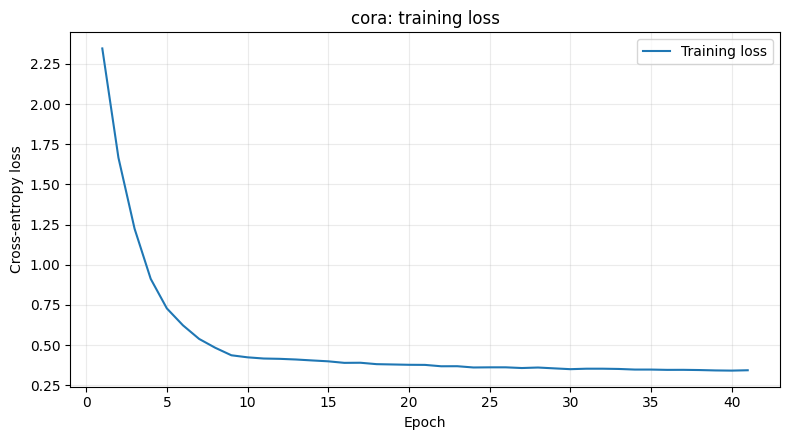

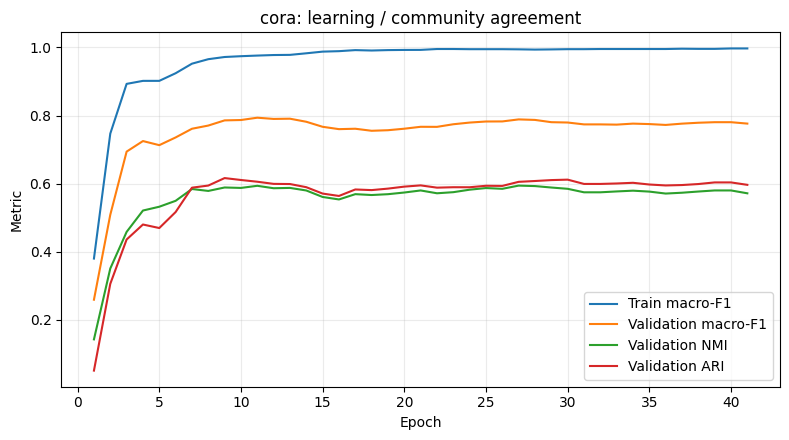

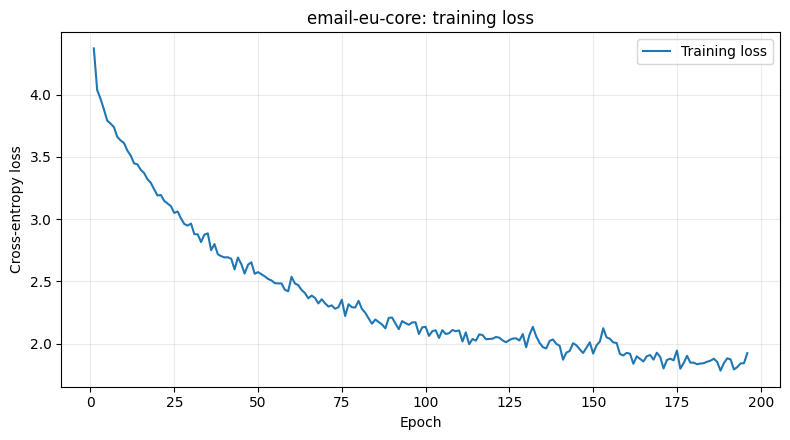

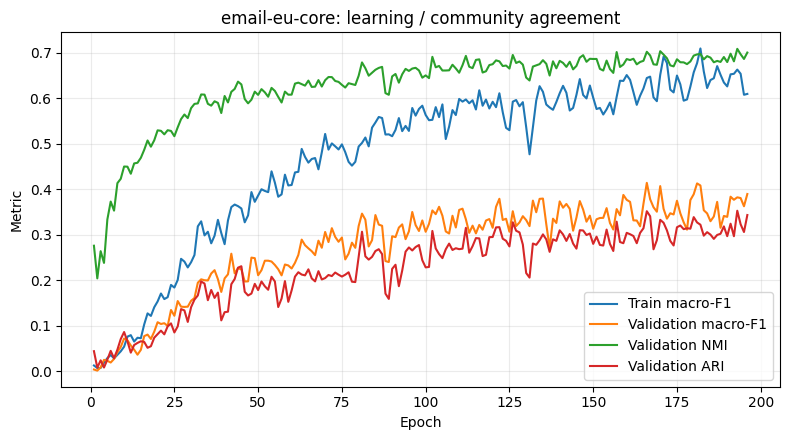

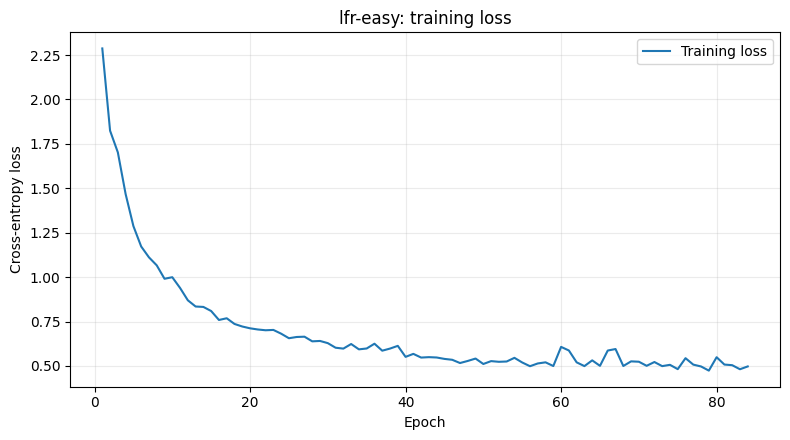

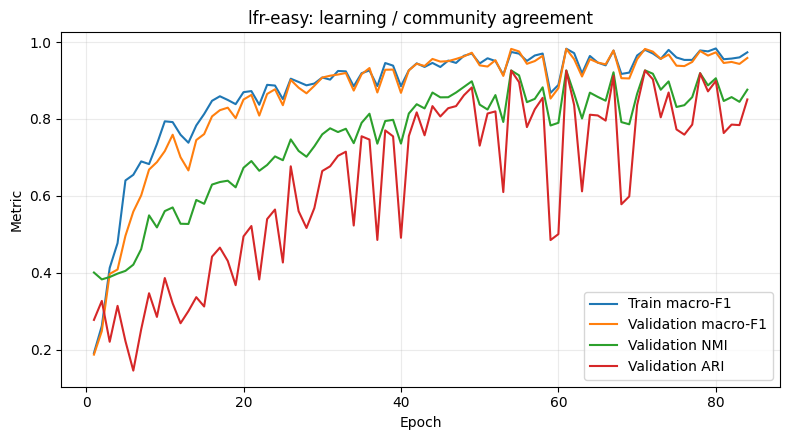

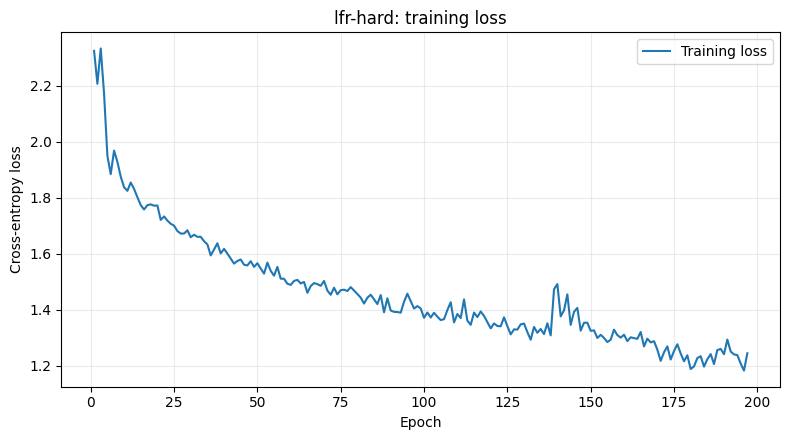

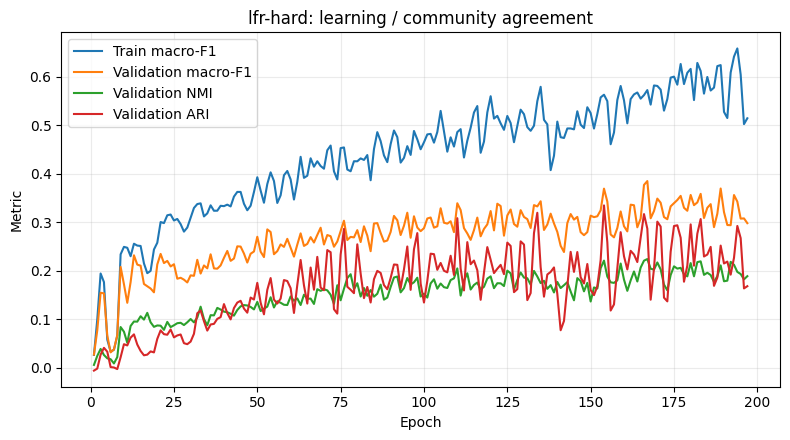

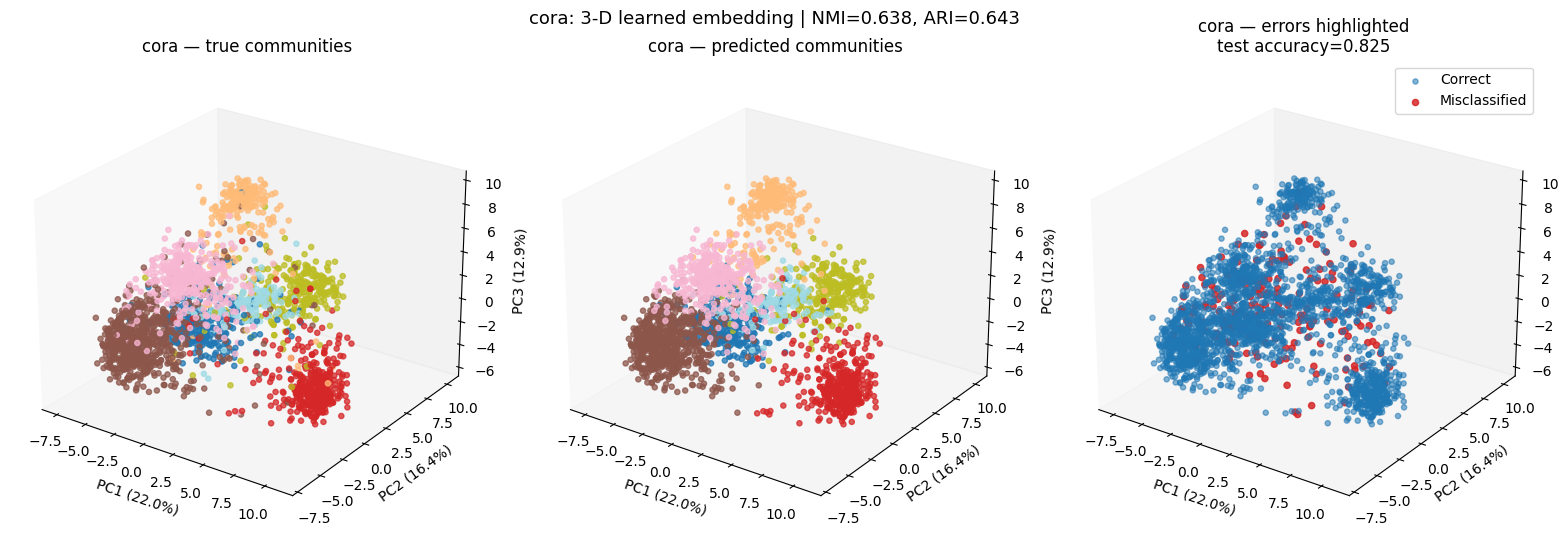

cora: PC1=22.0%, PC2=16.4%, PC3=12.9% (total=51.2%)


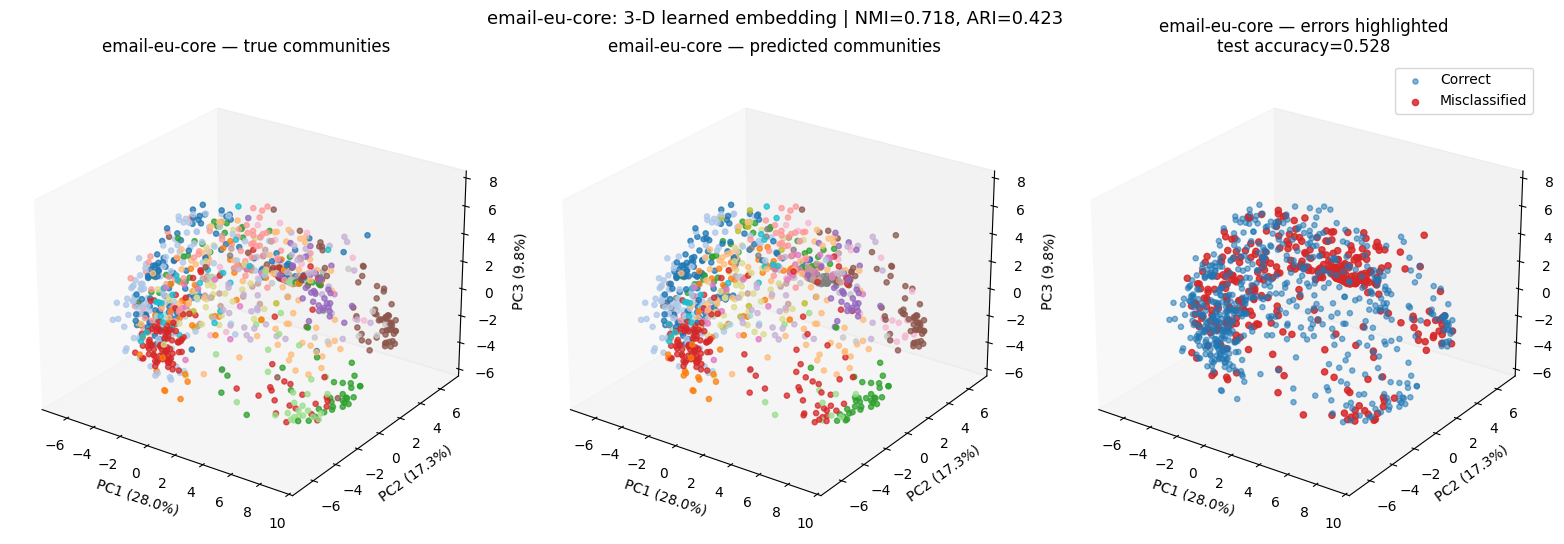

email-eu-core: PC1=28.0%, PC2=17.3%, PC3=9.8% (total=55.1%)


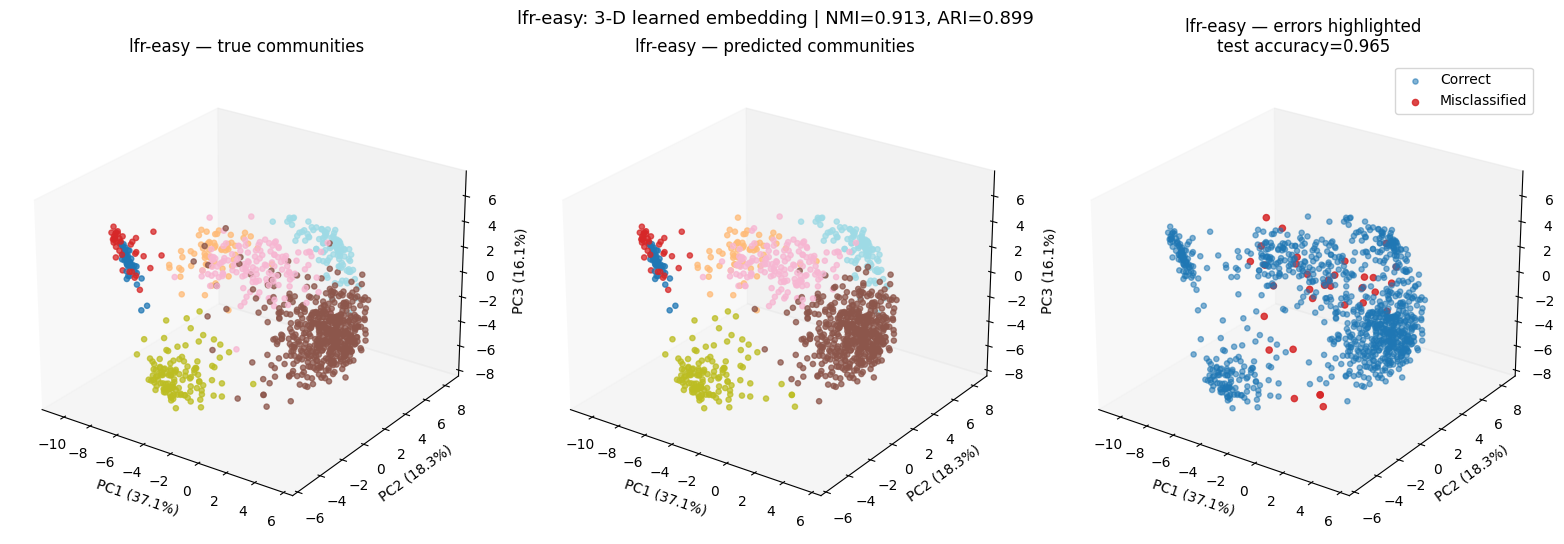

lfr-easy: PC1=37.1%, PC2=18.3%, PC3=16.1% (total=71.5%)


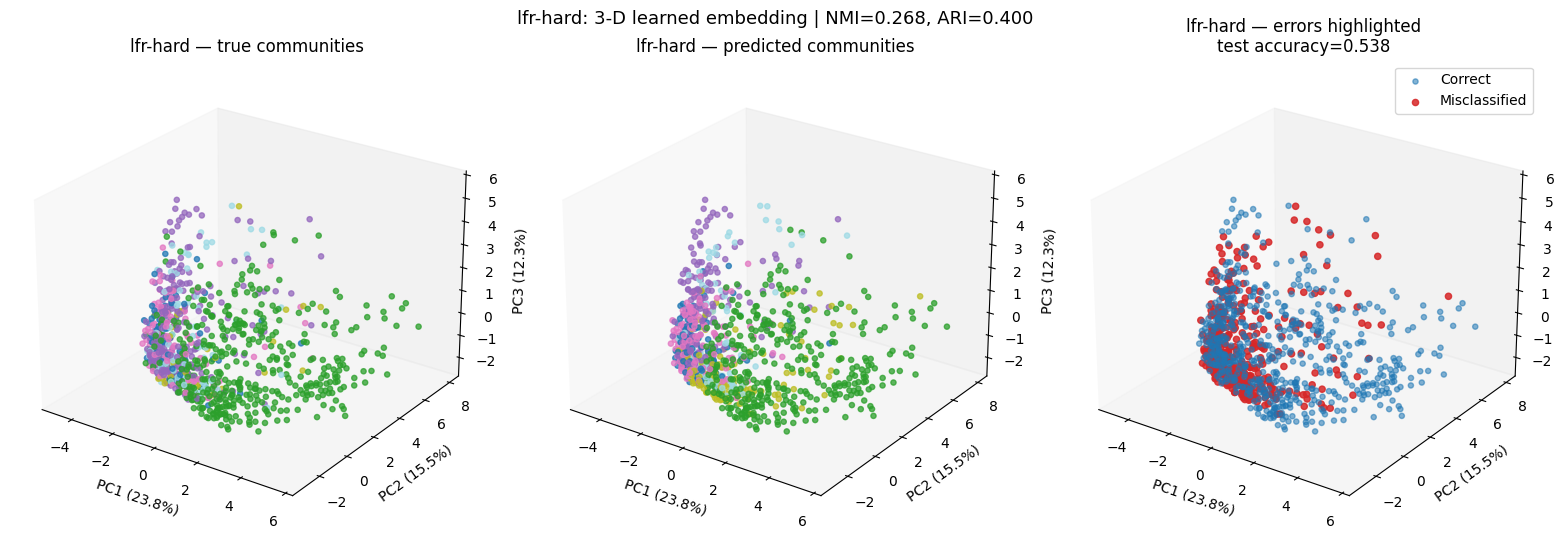

lfr-hard: PC1=23.8%, PC2=15.5%, PC3=12.3% (total=51.6%)


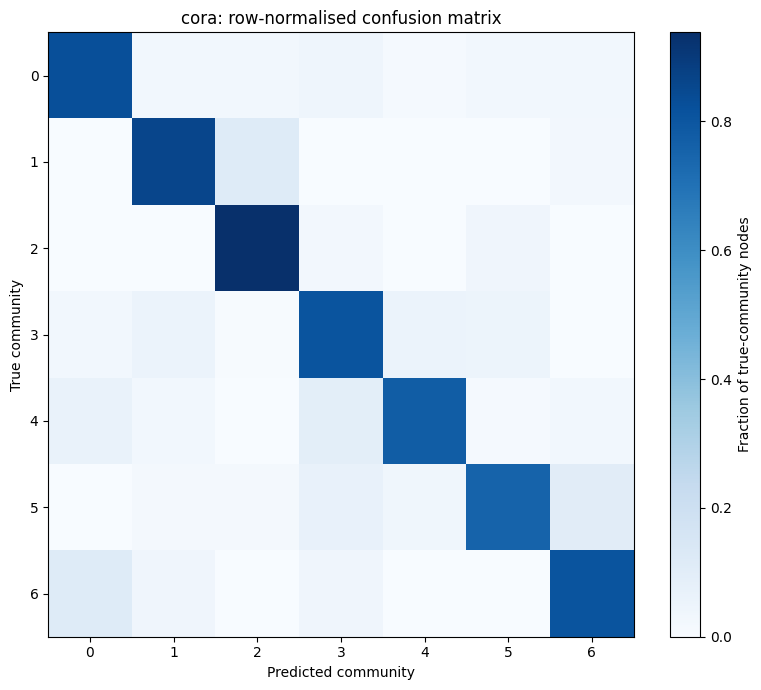

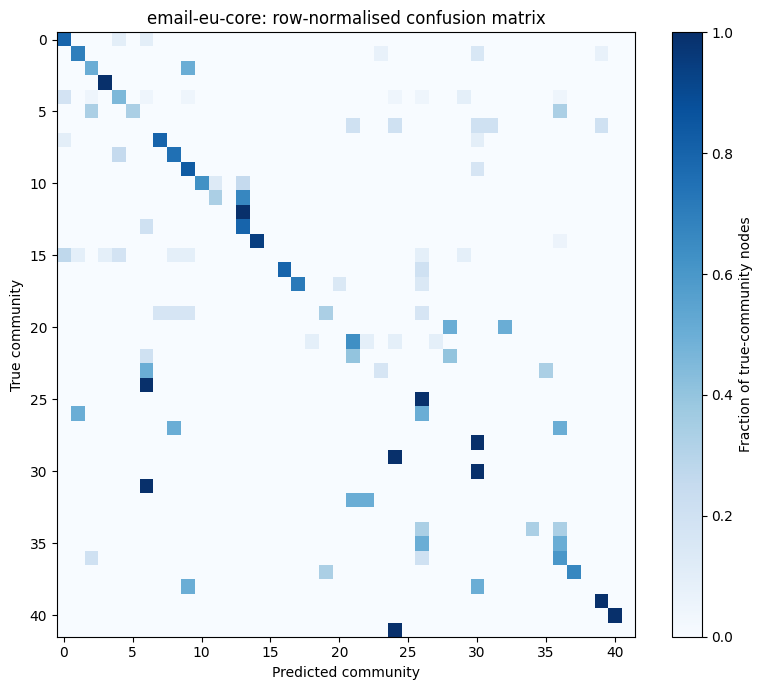

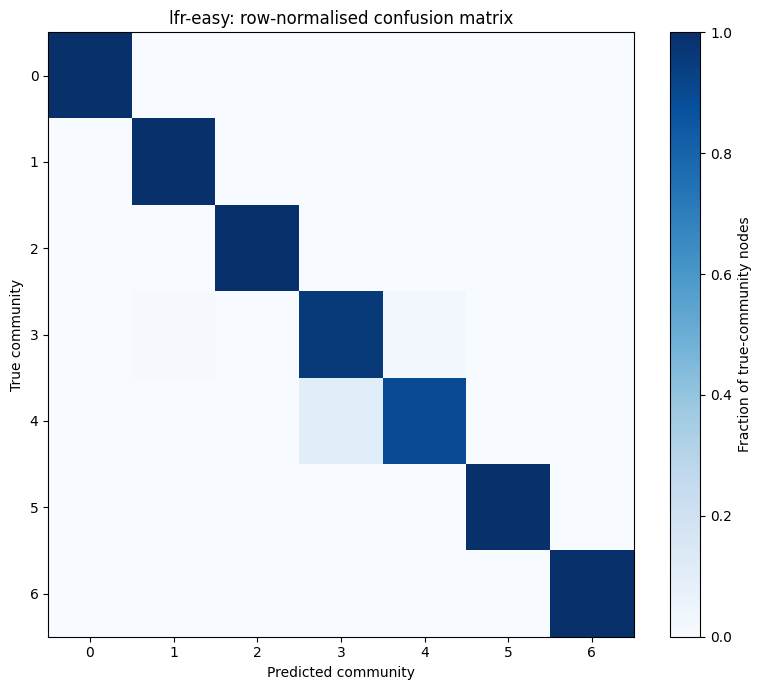

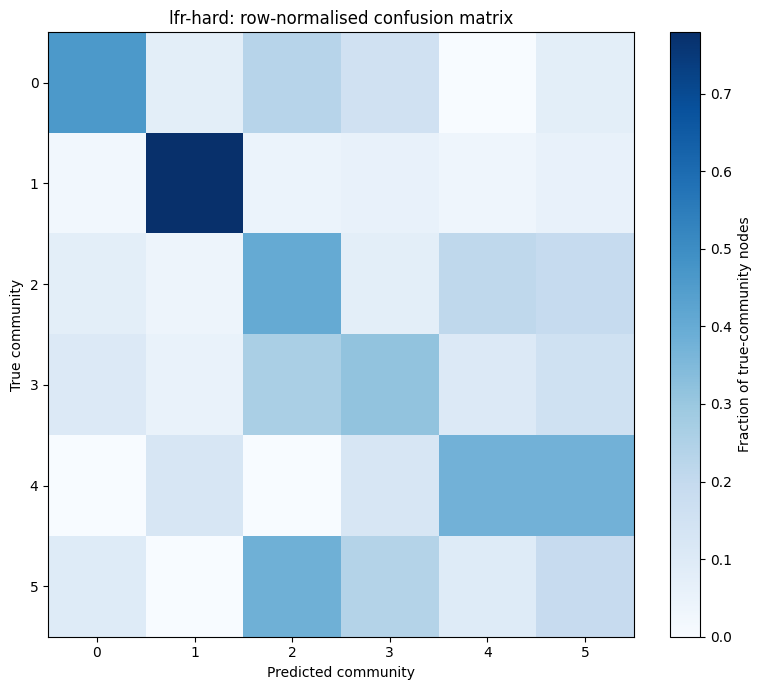

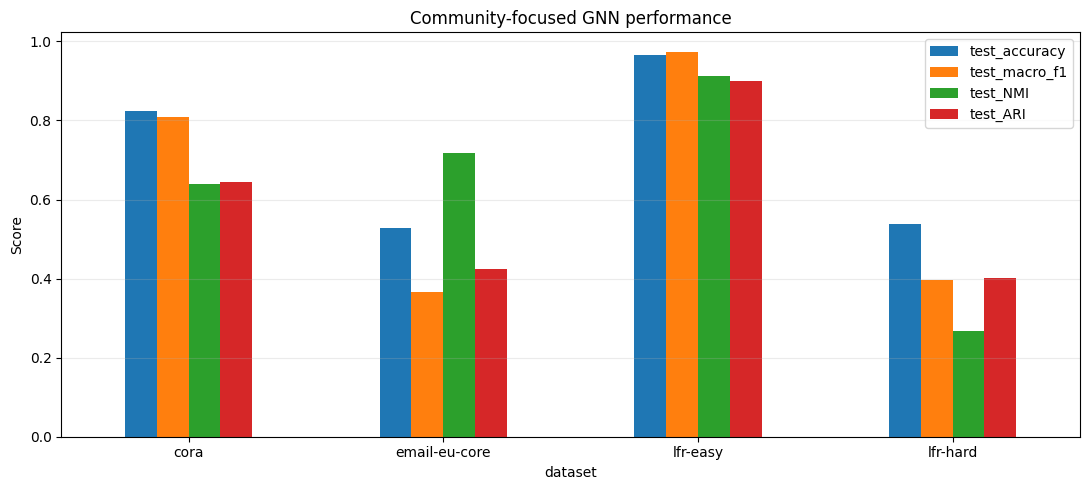

In [13]:
# final results + graphs
def plot_training_curves(name, run):
    h = run["history"]

    plt.figure(figsize=(8, 4.5))
    plt.plot(h["epoch"], h["loss"], label="Training loss")
    plt.xlabel("Epoch")
    plt.ylabel("Cross-entropy loss")
    plt.title(f"{name}: training loss")
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()

    if SAVE_FIGURES:
        plt.savefig(
            Path(FIGURE_DIR) / f"{name}_training_loss.png",
            dpi=180,
            bbox_inches="tight",
        )

    plt.show()

    plt.figure(figsize=(8, 4.5))
    plt.plot(h["epoch"], h["train_macro_f1"], label="Train macro-F1")
    plt.plot(h["epoch"], h["val_macro_f1"], label="Validation macro-F1")
    plt.plot(h["epoch"], h["val_NMI"], label="Validation NMI")
    plt.plot(h["epoch"], h["val_ARI"], label="Validation ARI")
    plt.xlabel("Epoch")
    plt.ylabel("Metric")
    plt.title(f"{name}: learning / community agreement")
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()

    if SAVE_FIGURES:
        plt.savefig(
            Path(FIGURE_DIR) / f"{name}_training_metrics.png",
            dpi=180,
            bbox_inches="tight",
        )

    plt.show()


for name, run in final_runs.items():
    plot_training_curves(name, run)

def plot_3d_classes(name, run, sample_limit=4000):
    bundle = datasets[name]
    y = bundle["y"].numpy()
    pred = run["pred"].numpy()
    embedding = run["embedding"].numpy()

    valid = y >= 0
    idx = np.flatnonzero(valid)

    rng = np.random.default_rng(SEED)
    if len(idx) > sample_limit:
        idx = rng.choice(idx, size=sample_limit, replace=False)

    coords = PCA(n_components=3, random_state=SEED).fit_transform(
        embedding[valid]
    )

    # PCA variance explanation for interpretation.
    pca = PCA(n_components=3, random_state=SEED)
    coords = pca.fit_transform(embedding[valid])
    explained = pca.explained_variance_ratio_

    # Map sampled original-valid positions.
    valid_positions = np.flatnonzero(valid)
    position_lookup = {node_idx: pos for pos, node_idx in enumerate(valid_positions)}
    sample_pos = np.array([position_lookup[i] for i in idx])

    correct = pred[idx] == y[idx]

    fig = plt.figure(figsize=(16, 5.5))

    ax1 = fig.add_subplot(1, 3, 1, projection="3d")
    sc1 = ax1.scatter(
        coords[sample_pos, 0],
        coords[sample_pos, 1],
        coords[sample_pos, 2],
        c=y[idx],
        cmap="tab20",
        s=14,
        alpha=0.75,
    )
    ax1.set_title(f"{name} — true communities")

    ax2 = fig.add_subplot(1, 3, 2, projection="3d")
    sc2 = ax2.scatter(
        coords[sample_pos, 0],
        coords[sample_pos, 1],
        coords[sample_pos, 2],
        c=pred[idx],
        cmap="tab20",
        s=14,
        alpha=0.75,
    )
    ax2.set_title(f"{name} — predicted communities")

    ax3 = fig.add_subplot(1, 3, 3, projection="3d")
    ax3.scatter(
        coords[sample_pos[correct], 0],
        coords[sample_pos[correct], 1],
        coords[sample_pos[correct], 2],
        c="tab:blue",
        s=14,
        alpha=0.55,
        label="Correct",
    )
    ax3.scatter(
        coords[sample_pos[~correct], 0],
        coords[sample_pos[~correct], 1],
        coords[sample_pos[~correct], 2],
        c="tab:red",
        s=20,
        alpha=0.85,
        label="Misclassified",
    )
    ax3.set_title(
        f"{name} — errors highlighted\n"
        f"test accuracy={run['result']['test_accuracy']:.3f}"
    )
    ax3.legend(loc="upper right")

    for ax in [ax1, ax2, ax3]:
        ax.set_xlabel(f"PC1 ({explained[0]*100:.1f}%)")
        ax.set_ylabel(f"PC2 ({explained[1]*100:.1f}%)")
        ax.set_zlabel(f"PC3 ({explained[2]*100:.1f}%)")
        ax.view_init(elev=25, azim=-55)
        ax.grid(False)

    fig.suptitle(
        f"{name}: 3-D learned embedding | "
        f"NMI={run['result']['test_NMI']:.3f}, "
        f"ARI={run['result']['test_ARI']:.3f}",
        fontsize=13,
    )

    plt.tight_layout()

    if SAVE_FIGURES:
        plt.savefig(
            Path(FIGURE_DIR) / f"{name}_3d_communities.png",
            dpi=180,
            bbox_inches="tight",
        )

    plt.show()

    print(
        f"{name}: PC1={explained[0]*100:.1f}%, "
        f"PC2={explained[1]*100:.1f}%, "
        f"PC3={explained[2]*100:.1f}% "
        f"(total={explained.sum()*100:.1f}%)"
    )


for name, run in final_runs.items():
    plot_3d_classes(name, run)

def plot_confusion(name, run):
    y = datasets[name]["y"].numpy()
    pred = run["pred"].numpy()
    test_mask = run["test_mask"].numpy()

    cm = confusion_matrix(
        y[test_mask],
        pred[test_mask],
        labels=np.arange(int(y[y >= 0].max() + 1)),
    )

    # Row-normalised matrix is easier to interpret with many communities.
    row_sums = cm.sum(axis=1, keepdims=True)
    cm_norm = np.divide(
        cm,
        row_sums,
        out=np.zeros_like(cm, dtype=float),
        where=row_sums != 0,
    )

    plt.figure(figsize=(8, 7))
    plt.imshow(cm_norm, aspect="auto", cmap="Blues")
    plt.colorbar(label="Fraction of true-community nodes")
    plt.xlabel("Predicted community")
    plt.ylabel("True community")
    plt.title(f"{name}: row-normalised confusion matrix")
    plt.tight_layout()

    if SAVE_FIGURES:
        plt.savefig(
            Path(FIGURE_DIR) / f"{name}_confusion_matrix.png",
            dpi=180,
            bbox_inches="tight",
        )

    plt.show()


for name, run in final_runs.items():
    plot_confusion(name, run)

# Compact performance comparison across datasets.
metric_cols = ["test_accuracy", "test_macro_f1", "test_NMI", "test_ARI"]

plot_df = final_df.set_index("dataset")[metric_cols]

ax = plot_df.plot(
    kind="bar",
    figsize=(11, 5),
    rot=0,
)
ax.set_ylabel("Score")
ax.set_title("Community-focused GNN performance")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()

if SAVE_FIGURES:
    plt.savefig(
        Path(FIGURE_DIR) / "overall_metric_comparison.png",
        dpi=180,
        bbox_inches="tight",
    )

plt.show()

In [14]:
# ## Final report-ready explanation
# 
# The next cell automatically produces a concise interpretation from the **measured results in this run**.
# 
# It deliberately distinguishes:
# - measured observations,
# - likely explanations,
# - and limitations that require more repeated runs.
# 
# This helps avoid claims such as “parameter X is universally best”.

def report_ready_analysis():
    print("=" * 90)
    print("REPORT-READY COMMUNITY-FOCUSED GNN ANALYSIS")
    print("=" * 90)

    print("\n1. Main performance table")
    display(
        final_df[
            [
                "dataset",
                "feature_source",
                "test_accuracy",
                "test_macro_f1",
                "test_NMI",
                "test_ARI",
                "best_epoch",
                "train_time_s",
            ]
        ].style.format({
            "test_accuracy": "{:.3f}",
            "test_macro_f1": "{:.3f}",
            "test_NMI": "{:.3f}",
            "test_ARI": "{:.3f}",
            "train_time_s": "{:.1f}",
        })
    )

    print("\n2. Dataset variation")
    nmi_min = final_df["test_NMI"].min()
    nmi_max = final_df["test_NMI"].max()
    ari_min = final_df["test_ARI"].min()
    ari_max = final_df["test_ARI"].max()

    print(
        f"Observed test NMI spans {nmi_min:.3f} to {nmi_max:.3f}; "
        f"test ARI spans {ari_min:.3f} to {ari_max:.3f}."
    )

    print(
        "This variation should be interpreted together with graph structure, "
        "community count, class balance, and feature informativeness."
    )

    print("\n3. Architecture-specific interpretation")
    print(
        "Unlike the previous VGAE + KMeans pipeline, the classifier is directly "
        "optimised for community labels. This removes the edge-reconstruction → "
        "KMeans objective mismatch from the main model."
    )

    print(
        "Accuracy and macro-F1 measure node-level classification. NMI and ARI "
        "measure agreement between the predicted and reference partitions."
    )

    print("\n4. Feature interpretation")
    print(
        "If structural features outperform degree-only features, the experiment "
        "supports the conclusion that richer graph-derived node information helps "
        "community classification on the tested graph."
    )
    print(
        "If Cora uses native features successfully, its result is more informative "
        "than the earlier degree-only fallback because the text-feature signal is "
        "actually aligned to the graph nodes."
    )

    if not sweep_df.empty:
        ranges = (
            sweep_df.groupby("factor")["test_NMI"]
            .agg(lambda s: float(s.mean()))
        )
        range_table = (
            sweep_df.groupby("factor")
            .agg(
                NMI_swing=("test_NMI", lambda s: float(s.mean())),
            )
        )

        factor_ranges = (
            sweep_summary.groupby("factor")
            .agg(
                NMI_swing=("mean_test_NMI", lambda s: float(s.max() - s.min())),
                ARI_swing=("mean_test_ARI", lambda s: float(s.max() - s.min())),
            )
            .sort_values("NMI_swing", ascending=False)
        )

        print("\n5. Hyperparameter sensitivity")
        display(factor_ranges)

        if len(factor_ranges):
            top_factor = factor_ranges.index[0]
            top_swing = factor_ranges.iloc[0]["NMI_swing"]
            print(
                f"The largest measured one-factor NMI swing was {top_swing:.3f} "
                f"for '{top_factor}' on {SWEEP_DATASET}."
            )

    if not ablation_df.empty:
        print("\n6. Ablation findings")

        grouped = (
            ablation_df.groupby(
                ["ablation_feature_mode", "ablation_class_weights"]
            )[["test_NMI", "test_ARI", "test_macro_f1"]]
            .mean()
        )
        display(grouped.style.format("{:.3f}"))

        print(
            "Ablation differences should be reported with the exact dataset, "
            "number of repeats, and tested settings because these are empirical "
            "results for the supplied datasets rather than universal laws."
        )

    print("\n7. Main factors affecting community performance")
    print(
        "The most important factors to discuss are: "
        "(a) how strongly graph connectivity reflects the reference communities; "
        "(b) how informative the node features are; "
        "(c) class imbalance across communities; "
        "(d) GNN depth and over-smoothing; "
        "(e) optimisation settings; and "
        "(f) random-seed variability."
    )

    print("\n8. Interpretation of PC1 / PC2 / PC3")
    print(
        "PC1, PC2 and PC3 are not community classes. They are the first three "
        "principal-component directions of the learned GNN embedding, used only "
        "to make a high-dimensional representation visible in 3-D. The percentages "
        "in the axis labels show how much embedding variance each component explains."
    )

    print("\n9. Important methodological limitation")
    print(
        "Because the model is trained using reference community labels, this notebook "
        "evaluates supervised/transductive community classification. It should not be "
        "presented as an unsupervised community-detection result. A separate unsupervised "
        "benchmark can be added when the scientific question requires no labels during training."
    )

report_ready_analysis()

# Save a final machine-readable combined table.
outputs = []

for name, run in final_runs.items():
    row = dict(run["result"])
    row["experiment_type"] = "final"
    outputs.append(row)

if not sweep_df.empty:
    sweep_out = sweep_df.copy()
    sweep_out["experiment_type"] = "hyperparameter_sweep"
    outputs.append(sweep_out)

combined_df = pd.concat(
    [
        pd.DataFrame([x]) if isinstance(x, dict) else x
        for x in outputs
    ],
    ignore_index=True,
)

combined_df.to_csv("community_gnn_all_experiments_cpu.csv", index=False)

print("Saved:")
print("  community_gnn_results_cpu.csv")
print("  community_gnn_hyperparameter_sweep_cpu.csv" if not sweep_df.empty else "  sweep disabled")
print("  community_gnn_ablation_cpu.csv" if not ablation_df.empty else "  ablation disabled")
print("  community_gnn_graph_stats_cpu.csv")
print("  community_gnn_all_experiments_cpu.csv")
print(f"Figures: {FIGURE_DIR}/")



REPORT-READY COMMUNITY-FOCUSED GNN ANALYSIS

1. Main performance table


,dataset,feature_source,test_accuracy,test_macro_f1,test_NMI,test_ARI,best_epoch,train_time_s
0,cora,cora-native,0.825,0.809,0.638,0.643,11,3.2
1,email-eu-core,structural,0.528,0.367,0.718,0.423,166,12.0
2,lfr-easy,structural,0.965,0.974,0.913,0.899,54,3.7
3,lfr-hard,structural,0.538,0.396,0.268,0.400,167,8.7



2. Dataset variation
Observed test NMI spans 0.268 to 0.913; test ARI spans 0.400 to 0.899.
This variation should be interpreted together with graph structure, community count, class balance, and feature informativeness.

3. Architecture-specific interpretation
Unlike the previous VGAE + KMeans pipeline, the classifier is directly optimised for community labels. This removes the edge-reconstruction → KMeans objective mismatch from the main model.
Accuracy and macro-F1 measure node-level classification. NMI and ARI measure agreement between the predicted and reference partitions.

4. Feature interpretation
If structural features outperform degree-only features, the experiment supports the conclusion that richer graph-derived node information helps community classification on the tested graph.
If Cora uses native features successfully, its result is more informative than the earlier degree-only fallback because the text-feature signal is actually aligned to the graph nodes.

5. Hyperpar

,NMI_swing,ARI_swing
factor,,
layers,0.142311,0.167576
lr,0.087067,0.100607
weight_decay,0.050332,0.055258
dropout,0.050332,0.056246
hidden,0.035266,0.040902
label_smoothing,0.034814,0.042888


The largest measured one-factor NMI swing was 0.142 for 'layers' on lfr-easy.

6. Ablation findings


Ablation differences should be reported with the exact dataset, number of repeats, and tested settings because these are empirical results for the supplied datasets rather than universal laws.

7. Main factors affecting community performance
The most important factors to discuss are: (a) how strongly graph connectivity reflects the reference communities; (b) how informative the node features are; (c) class imbalance across communities; (d) GNN depth and over-smoothing; (e) optimisation settings; and (f) random-seed variability.

8. Interpretation of PC1 / PC2 / PC3
PC1, PC2 and PC3 are not community classes. They are the first three principal-component directions of the learned GNN embedding, used only to make a high-dimensional representation visible in 3-D. The percentages in the axis labels show how much embedding variance each component explains.

9. Important methodological limitation
Because the model is trained using reference community labels, this notebook evaluates supervised